# 05 — Quand et pourquoi la TTA échoue
Sources : `results/failure_{batch,noniid,layers}_<bb>.csv`.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R, F = ROOT / "results", ROOT / "figures"
pd.set_option("display.precision", 3); pd.set_option("display.width", 200)
def fig(name):
    p = F / f"{name}.png"
    display(Image(str(p))) if p.exists() else print("missing figure:", p.name)
def csv(name):
    p = R / name
    return pd.read_csv(p) if p.exists() else print("missing table:", p.name)

In [2]:
for bb in ['vit_s16', 'resnet50']:
    b = csv(f'failure_batch_{bb}.csv')
    if b is not None:
        display(Markdown(f'**{bb} — taille de batch**'))
        display(b.groupby(['method', 'condition', 'batch_size']).acc.mean().unstack())

missing table: failure_batch_vit_s16.csv


**resnet50 — taille de batch**

batch_size                          8      64
method condition                             
bn     S_test:gaussian_noise_s3  0.220  0.248
       S_test:motion_blur_s3     0.217  0.283
       W_test:clean              0.453  0.455
source S_test:gaussian_noise_s3  0.105  0.105
       S_test:motion_blur_s3     0.178  0.177
       W_test:clean              0.453  0.452
tent   S_test:gaussian_noise_s3  0.068  0.292
       S_test:motion_blur_s3     0.066  0.311
       W_test:clean              0.141  0.463

In [3]:
for bb in ['vit_s16', 'resnet50']:
    b = csv(f'failure_noniid_{bb}.csv')
    if b is not None:
        display(Markdown(f'**{bb} — flux i.i.d. vs triés par classe**'))
        display(b.groupby(['method', 'order']).agg(acc=('acc','mean'), n_pred_classes=('n_pred_classes','mean')).unstack())

**vit_s16 — flux i.i.d. vs triés par classe**

acc        n_pred_classes        
order    class_sorted    iid   class_sorted     iid
method                                             
anchored        0.682  0.681         99.833  99.667
eata            0.692  0.691         99.833  99.833
lame            0.713  0.675         99.500  99.500
source          0.682  0.682         99.667  99.667
tent            0.687  0.692        100.000  99.833

missing table: failure_noniid_resnet50.csv


missing figure: 09_failure_batch_vit_s16.png


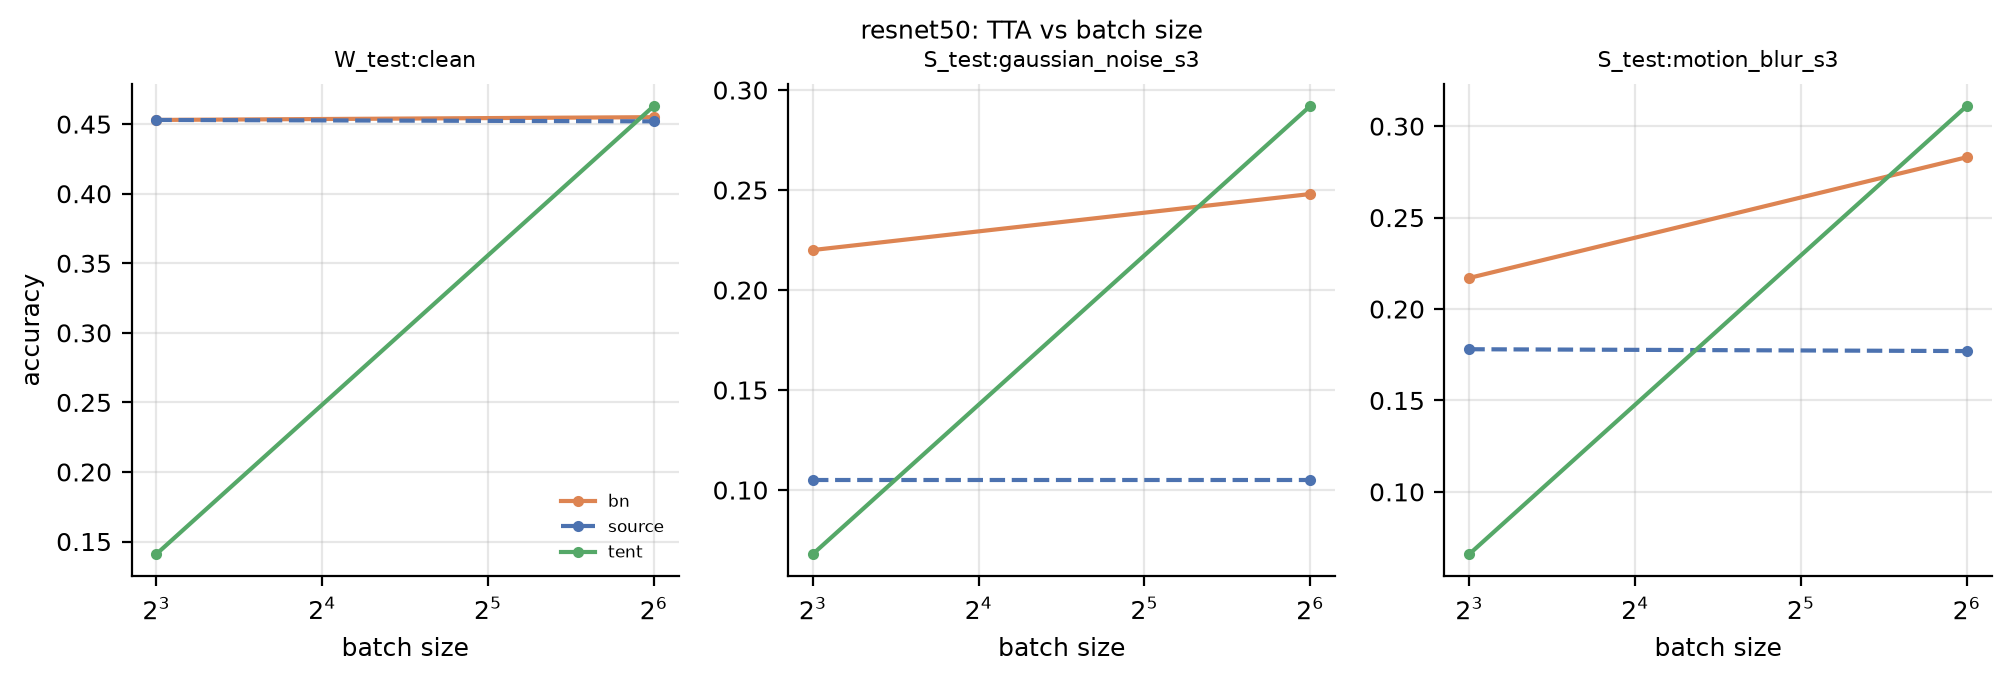

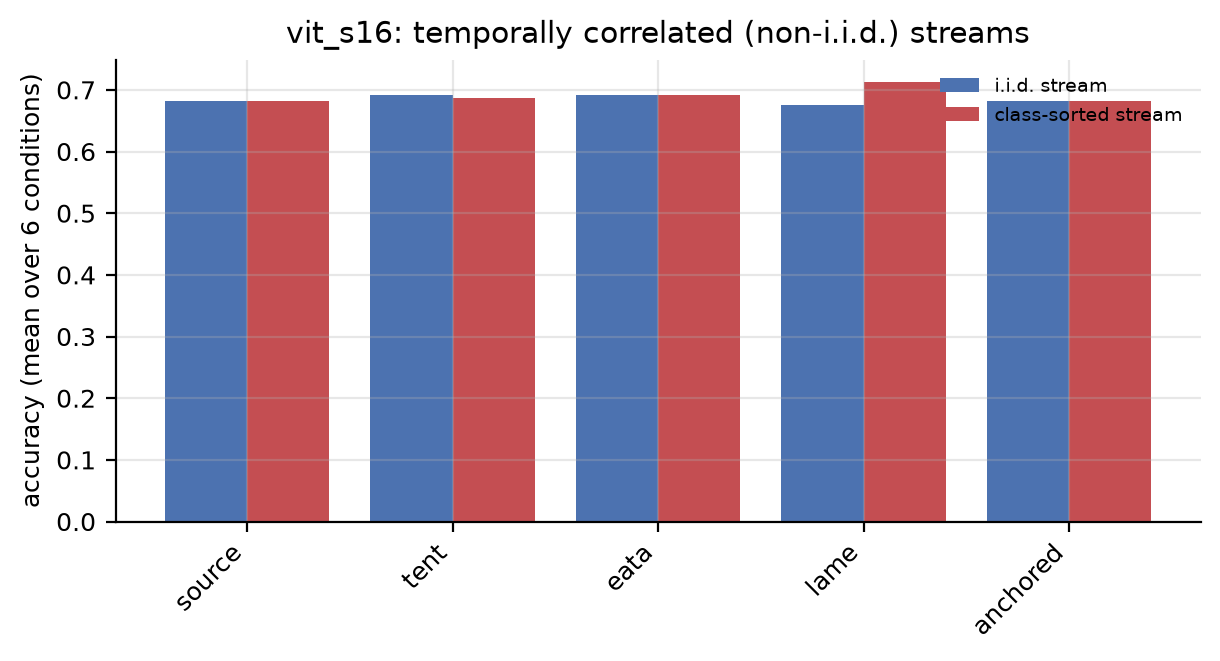

missing figure: 09_failure_noniid_resnet50.png


In [4]:
for n in ['09_failure_batch', '09_failure_noniid']:
    for bb in ['vit_s16', 'resnet50']:
        fig(f'{n}_{bb}')